# Stock movement forecasting using LOB

Before start, we need to test some libraries in order to build a reasonable dataset for the neural network architecture.

In [26]:
import time 
import pandas
import random
import json, argparse

# ML
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from plotly import graph_objects as go
from sklearn import preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.metrics import confusion_matrix, roc_auc_score, classification_report

# pytorch
import torch.nn as nn
import torch
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import torch.optim as optim
import torch.utils

# software modules
import models_classification as Models
import utils
import dataset as Dataset

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print('Using device:', device)

Using device: cuda:0


## Load Data

In [27]:
df = pd.read_parquet('./Data/FI-2010-Cleaned/NoAuction/Zscore/WRT1V.parquet')
df.drop(columns=['Day'], inplace=True)
df = df.head(1000)

target_cols = ['Label_10', 'Label_20', 'Label_30', 'Label_50', 'Label_100']
# Set target cols to dtype int
df[target_cols] = df[target_cols].astype(int)

df.head()

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,Label_10,Label_20,Label_30,Label_50,Label_100
0,1.242406,-0.611621,1.240199,-0.446819,1.241779,-0.663252,1.240732,-0.512393,1.241182,-0.770717,...,-0.499588,1.236425,-0.444236,1.243820,-0.278126,1,1,1,1,1
1,1.241385,-0.678429,1.240199,-0.555044,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1,1,1,1,1
2,1.241385,-0.678429,1.240199,-0.465970,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1,1,1,1,1
3,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,-0.339924,1.233373,-0.228680,1.245871,-0.448846,2,2,1,1,1
4,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1,0,0,1,1


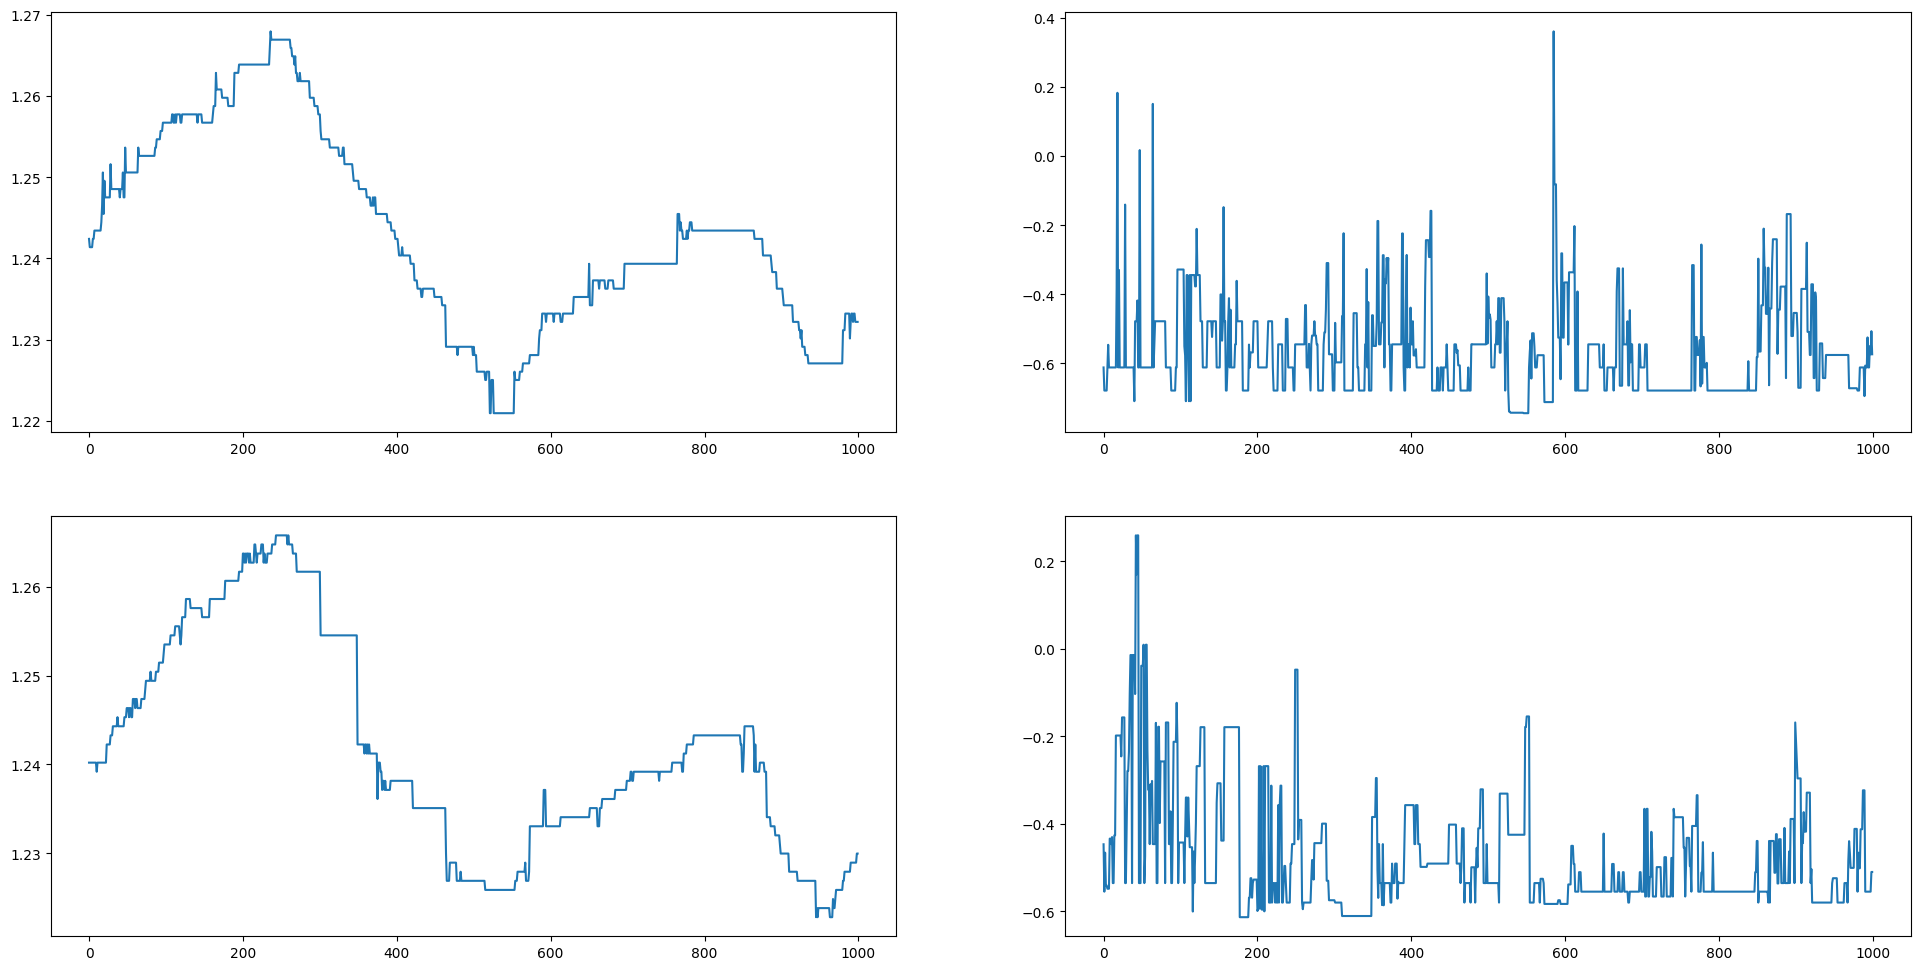

In [28]:
_, axs = plt.subplots(2, 2, figsize=(24,12))
axs[0,0].plot(df['P_Ask_1'])
axs[0,1].plot(df['V_Ask_1'])
axs[1,0].plot(df['P_Bid_1'])
axs[1,1].plot(df['V_Bid_1'])
plt.show()

In [29]:
logreturn = lambda x: np.log(x) - np.log(x.shift(1))

price_cols = [col for col in df.columns if 'P_' in col]
df[price_cols] = df[price_cols].apply(logreturn, axis=0)
df.dropna(inplace=True)

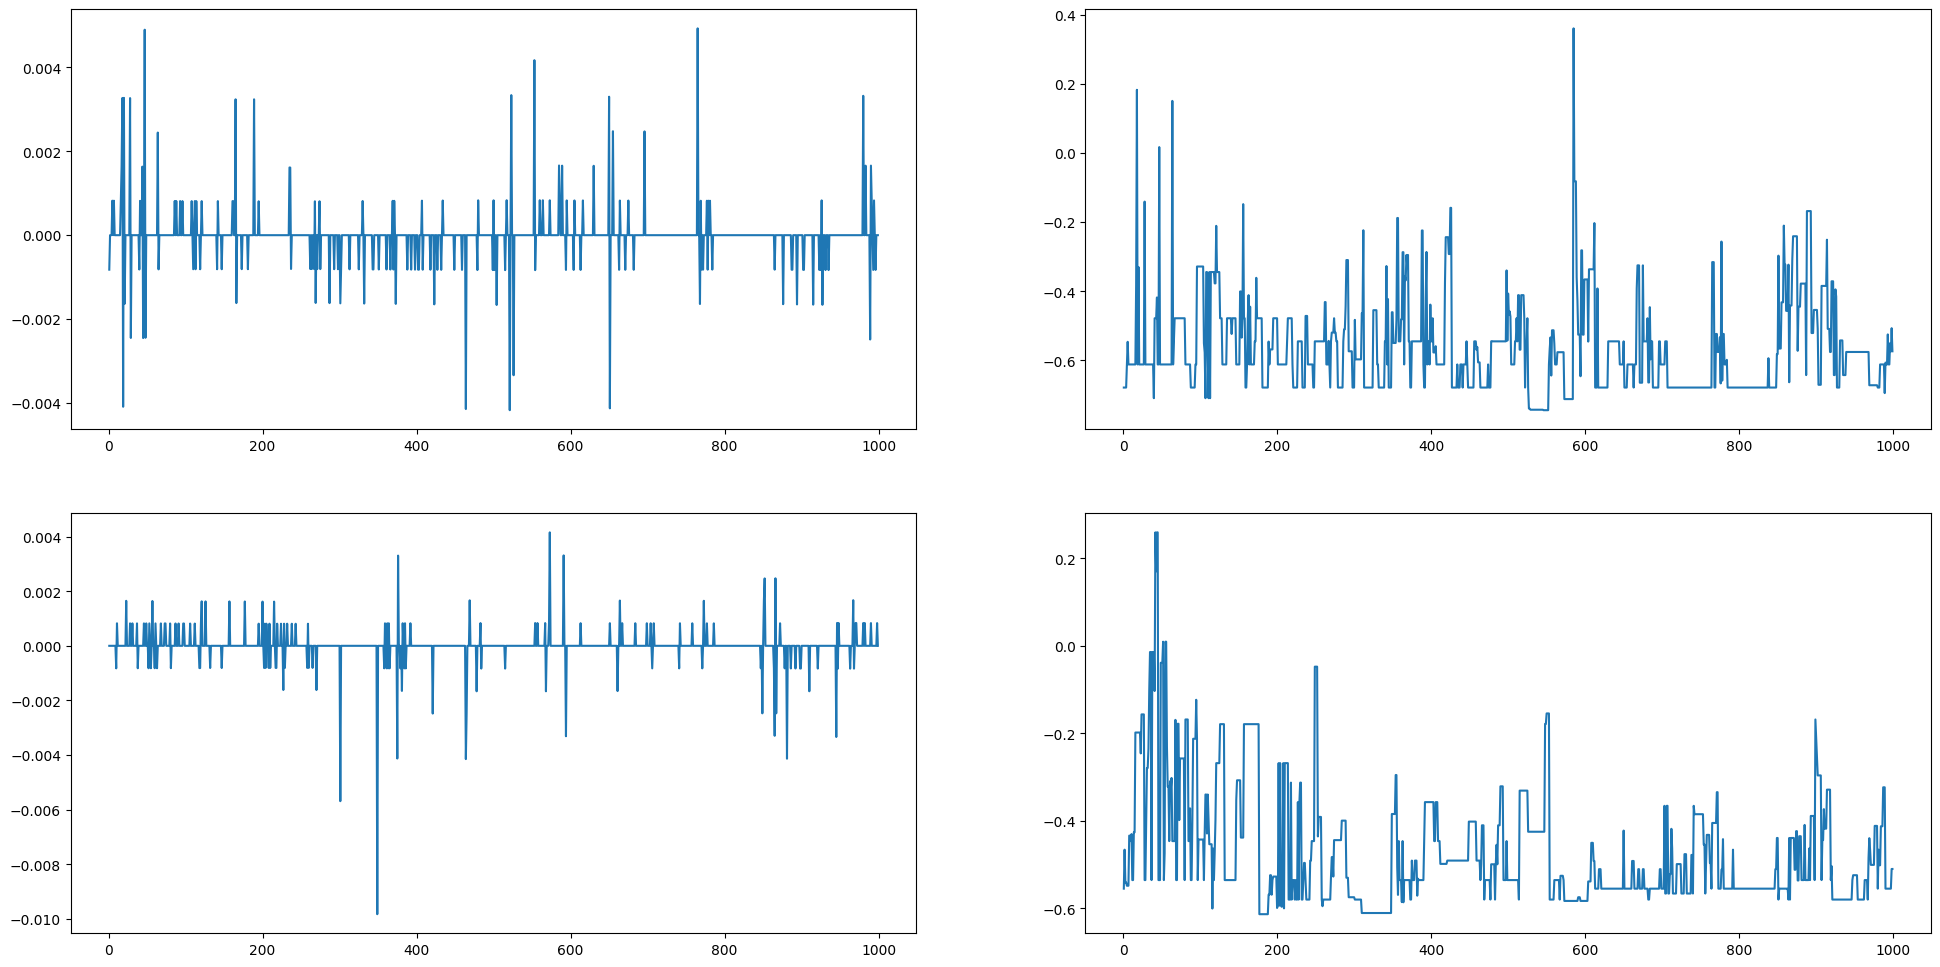

In [30]:
_, axs = plt.subplots(2, 2, figsize=(24,12))
axs[0,0].plot(df['P_Ask_1'])
axs[0,1].plot(df['V_Ask_1'])
axs[1,0].plot(df['P_Bid_1'])
axs[1,1].plot(df['V_Bid_1'])
plt.show()

In [31]:
# Split the dataframe into train and test
df_train, df_val, df_test = utils.DataTools.train_val_test_split(df)

# Split covariates and response variable(s)
X_train, y_train = utils.DataTools.split_x_y(df_train, target_cols)
X_val, y_val     = utils.DataTools.split_x_y(df_val, target_cols)
X_test, y_test   = utils.DataTools.split_x_y(df_test, target_cols)

# Standardize the covariates
scaler_X = preprocessing.StandardScaler()
X_train = scaler_X.fit_transform(X_train)
X_val = scaler_X.transform(X_val)
X_test = scaler_X.transform(X_test)

# Build tensors 
X_train, X_val, X_test = utils.DataTools.numpy_to_tensor( X_train, X_val, X_test, device=device, dtype=torch.float32 )
y_train, y_val, y_test = utils.DataTools.numpy_to_tensor( y_train, y_val, y_test, device=device, dtype=torch.long )

# Build TimeSeriesDataset
SEQ_LEN_X = 50
SEQ_LEN_Y = 1
OFFSET = 0
dataset_train = Dataset.TimeSeriesDataset(
    X         = X_train,
    y         = y_train,
    seq_len_x = SEQ_LEN_X,
    seq_len_y = SEQ_LEN_Y,
    offset    = OFFSET,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.CLASSIFICATION
)
dataset_val = Dataset.TimeSeriesDataset(
    X         = X_val,
    y         = y_val,
    seq_len_x = SEQ_LEN_X,
    seq_len_y = SEQ_LEN_Y,
    offset    = OFFSET,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.CLASSIFICATION
)
dataset_test = Dataset.TimeSeriesDataset(
    X         = X_test,
    y         = y_test,
    seq_len_x = SEQ_LEN_X,
    seq_len_y = SEQ_LEN_Y,
    offset    = OFFSET,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.CLASSIFICATION
)

# Build TimeSeriesLoader
BATCH_SIZE = 32
dataloader_train = Dataset.TimeSeriesLoader(
    dataset = dataset_train,
    batch_size = BATCH_SIZE,
    shuffle = True
)
dataloader_val = Dataset.TimeSeriesLoader(
    dataset = dataset_val,
    batch_size = BATCH_SIZE,
    shuffle = False
)
dataloader_test = Dataset.TimeSeriesLoader(
    dataset = dataset_test,
    batch_size = 1024,
    shuffle = False
)

In [32]:
print(f'Train dataset: {len(dataset_train)} samples')
print(f'Test dataset: {len(dataset_test)} samples')

Train dataset: 649 samples
Test dataset: 101 samples


## Models

In [33]:
def loss_fn(y_pred, y, criterion = nn.CrossEntropyLoss() ):
    loss = 0
    for i in range(y_pred.shape[1]):
        loss += criterion(y_pred[:, i, :], y[:, i])
    return loss

### Basic LSTM

In [34]:
dataloader_train.dataset.channels = False
dataloader_val.dataset.channels = False
dataloader_test.dataset.channels = False

In [35]:
# Create the model
params = {
    'input_size': X_train.shape[1],
    'output_size': 3*y_train.shape[1],
    'hidden_size': 64,
    'num_layers': 2,
    'dropout_rate': 0.15
}
model = Models.LSTM(**params).to(device)

# Define loss function and optimizer
learning_rate = 1e-3
n_epochs = 3
criterion = loss_fn
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info = utils.ModelTools.train(
    model_id = 'Basic LSTM',
    model = model,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = n_epochs,
    save = False,
    device = device
)

Training:   0%|          | 0/3 [00:00<?, ?it/s]

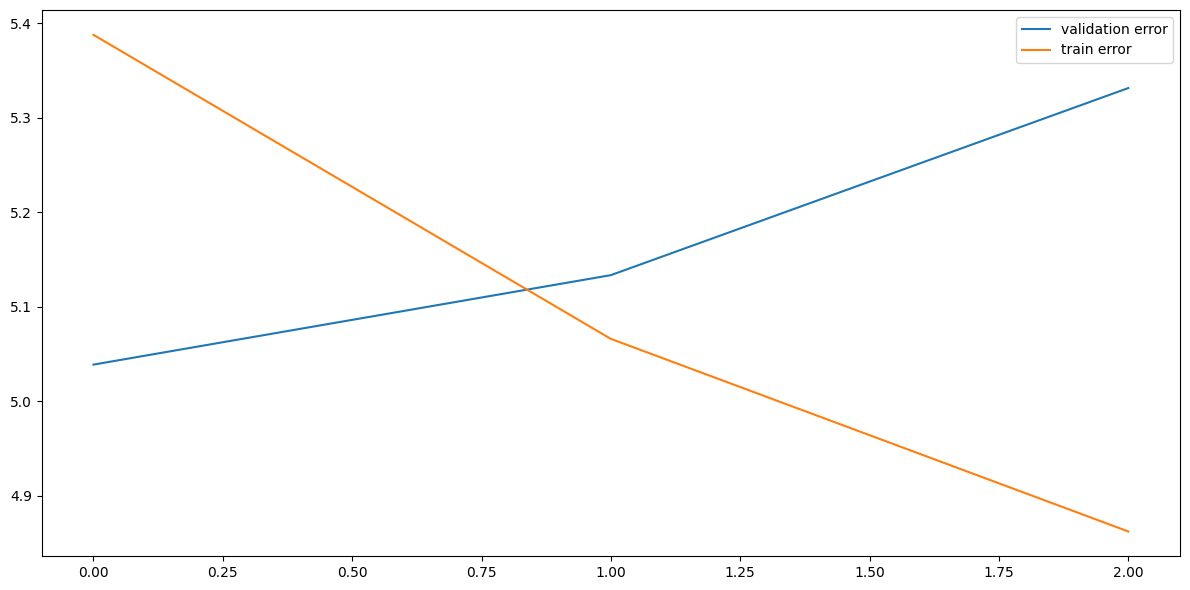

In [36]:
epochs_list = list(range(0,n_epochs))
plt.figure(figsize=(12,6))
plt.plot(epochs_list, training_info['val_loss'],  label = "validation error")
plt.plot(epochs_list, training_info['train_loss'], label = "train error")
plt.legend(loc = 'best')
plt.tight_layout()
plt.show()

In [37]:
true = []
pred = []

# Evaluate the model
with torch.no_grad():
    for inputs, labels in dataloader_test:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        true.append(labels.cpu().numpy())
        pred.append(outputs.cpu().numpy())

true = np.concatenate(true, axis=0)
pred = np.concatenate(pred, axis=0)
pred = np.argmax(pred, axis=2)

Save stuff

In [38]:
# Save the model
torch.save(model.state_dict(), './ModelsCheckpoints/BasicLSTM.pth')

# Save true and pred
np.save('./ModelsCheckpoints/BasicLSTM_true.npy', true)
np.save('./ModelsCheckpoints/BasicLSTM_pred.npy', pred)

In [ ]:
conf_matrixes = []
for i in range(true.shape[1]):
    conf_matrix = confusion_matrix(true[:, i], pred[:, i], normalize='true')
    conf_matrixes.append(conf_matrix)
    
fig, axs = plt.subplots(1, true.shape[1], figsize=(20, 4))
for i, ax in enumerate(axs):
    sns.heatmap(conf_matrixes[i], annot=True, cmap='Blues', ax=ax)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(f'Horizon {i+1}')
plt.show()

In [ ]:
# 5 classification reports
for i in range(true.shape[1]):
    print(f'Classification report {i}')
    print(classification_report(true[:, i], pred[:, i], zero_division=0))
    print('\n')

### Astice

In [ ]:
dataloader_train.dataset.channels = False
dataloader_val.dataset.channels = False
dataloader_test.dataset.channels = False

In [ ]:
# Create the model
params = {
    'input_size': X_train.shape[1],
    'output_size': 3*y_train.shape[1],
    'hidden_size': 64,
    'lstm_size': 64,
    'smooth_conv_channels': 8,
    'dropout_rate': 0.15
}
model = Models.Astice(**params).to(device)

# Define loss function and optimizer
learning_rate = 1e-3
n_epochs = 3
criterion = loss_fn
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info = utils.ModelTools.train(
    model_id = 'Astice',
    model = model,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = n_epochs,
    save = False,
    device = device
)

In [ ]:
epochs_list = list(range(0,n_epochs))
plt.figure(figsize=(12,6))
plt.plot(epochs_list, training_info['val_loss'],  label = "validation error")
plt.plot(epochs_list, training_info['train_loss'], label = "train error")
plt.legend(loc = 'best')
plt.tight_layout()
plt.show()

In [ ]:
true = []
pred = []

# Evaluate the model
with torch.no_grad():
    for inputs, labels in dataloader_test:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        true.append(labels.cpu().numpy())
        pred.append(outputs.cpu().numpy())

true = np.concatenate(true, axis=0)
pred = np.concatenate(pred, axis=0)
pred = np.argmax(pred, axis=2)

Save stuff

In [ ]:
# Save the model
torch.save(model.state_dict(), './ModelsCheckpoints/Astice.pth')

# Save true and pred
np.save('./ModelsCheckpoints/Astice_true.npy', true)
np.save('./ModelsCheckpoints/Astice_pred.npy', pred)

In [ ]:
conf_matrixes = []
for i in range(true.shape[1]):
    conf_matrix = confusion_matrix(true[:, i], pred[:, i], normalize='true')
    conf_matrixes.append(conf_matrix)
    
fig, axs = plt.subplots(1, true.shape[1], figsize=(20, 4))
for i, ax in enumerate(axs):
    sns.heatmap(conf_matrixes[i], annot=True, cmap='Blues', ax=ax)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(f'Horizon {i+1}')
plt.show()

In [ ]:
# 5 classification reports
for i in range(true.shape[1]):
    print(f'Classification report {i}')
    print(classification_report(true[:, i], pred[:, i], zero_division=0))
    print('\n')

### Marmotta

In [ ]:
dataloader_train.dataset.channels = False
dataloader_val.dataset.channels = False
dataloader_test.dataset.channels = False

In [ ]:
# Create the model
params = {
    'input_size': X_train.shape[1],
    'output_size': 3,
    'hidden_size': 64,
    'dropout_rate': 0.15,
    'seq_len_in': 50,
    'seq_len_out': 5,
    'device': device
}
model = Models.Marmotta(**params).to(device)

# Define loss function and optimizer
learning_rate = 1e-3
n_epochs = 3
criterion = loss_fn
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info = utils.ModelTools.train(
    model_id = 'Marmotta',
    model = model,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = n_epochs,
    save = False,
    device = device
)

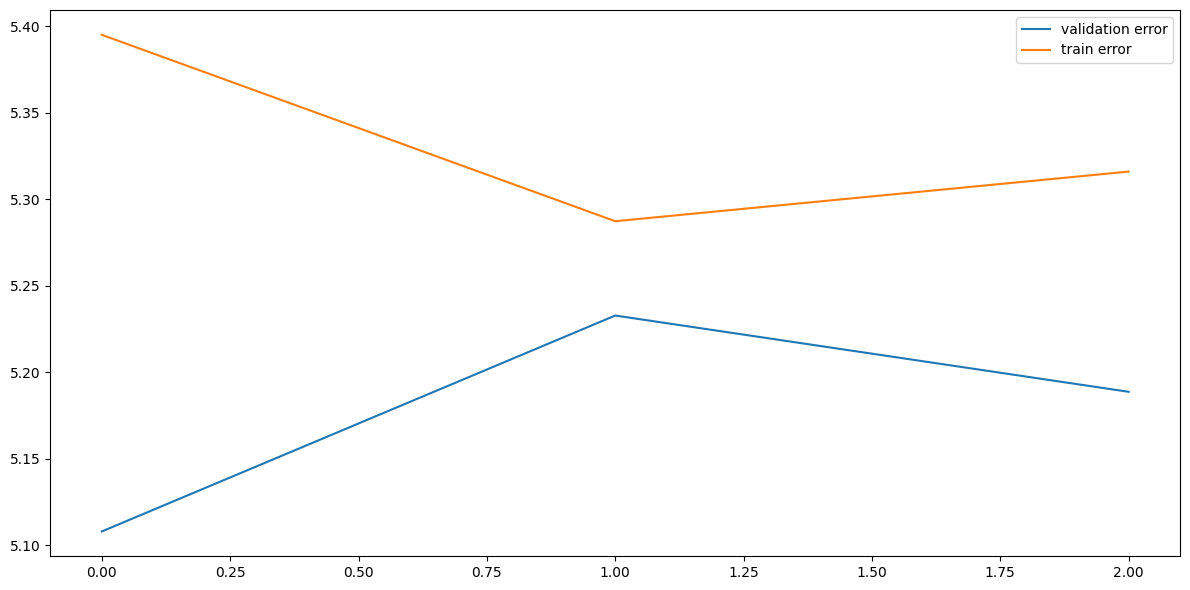

In [22]:
epochs_list = list(range(0,n_epochs))
plt.figure(figsize=(12,6))
plt.plot(epochs_list, training_info['val_loss'],  label = "validation error")
plt.plot(epochs_list, training_info['train_loss'], label = "train error")
plt.legend(loc = 'best')
plt.tight_layout()
plt.show()

In [23]:
true = []
pred = []

# Evaluate the model
with torch.no_grad():
    for inputs, labels in dataloader_test:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        true.append(labels.cpu().numpy())
        pred.append(outputs.cpu().numpy())

true = np.concatenate(true, axis=0)
pred = np.concatenate(pred, axis=0)
pred = np.argmax(pred, axis=2)

Save stuff

In [ ]:
# Save the model
torch.save(model.state_dict(), './ModelsCheckpoints/Marmotta.pth')

# Save true and pred
np.save('./ModelsCheckpoints/Marmotta_true.npy', true)
np.save('./ModelsCheckpoints/Marmotta_pred.npy', pred)

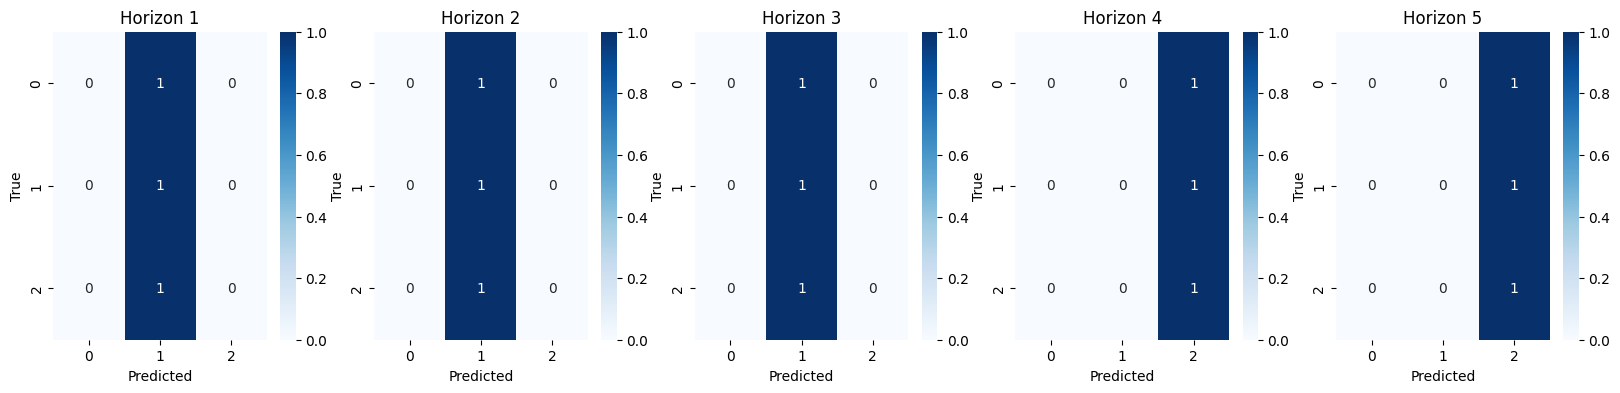

In [24]:
conf_matrixes = []
for i in range(true.shape[1]):
    conf_matrix = confusion_matrix(true[:, i], pred[:, i], normalize='true')
    conf_matrixes.append(conf_matrix)
    
fig, axs = plt.subplots(1, true.shape[1], figsize=(20, 4))
for i, ax in enumerate(axs):
    sns.heatmap(conf_matrixes[i], annot=True, cmap='Blues', ax=ax)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(f'Horizon {i+1}')
plt.show()

In [25]:
# 5 classification reports
for i in range(true.shape[1]):
    print(f'Classification report {i}')
    print(classification_report(true[:, i], pred[:, i], zero_division=0))
    print('\n')

Classification report 0
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         8
           1       0.53      1.00      0.70        54
           2       0.00      0.00      0.00        39

    accuracy                           0.53       101
   macro avg       0.18      0.33      0.23       101
weighted avg       0.29      0.53      0.37       101



Classification report 1
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         9
           1       0.40      1.00      0.57        40
           2       0.00      0.00      0.00        52

    accuracy                           0.40       101
   macro avg       0.13      0.33      0.19       101
weighted avg       0.16      0.40      0.22       101



Classification report 2
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         9
           1       0.26      1.00      0.41        26